# Projet — Prédiction de trajectoire

**Cours :** Réseaux de neurones récurrents (RNN) — 20 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 3 h · **Barème :** 20 points

---

## Objectifs

- Mener un projet complet : données, modèle, entraînement, évaluation.
- Comparer à une référence naïve.
- Analyser les cas d'échec.

## Travail demandé

1. Mener le projet jusqu'au bout.
2. Ajouter une expérience contrôlée mesurée.
3. Rendre le notebook exécuté avec une conclusion écrite.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU.
- Les cellules **« À vous »** sont évaluées ; graines fixées.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)

## Projet — prédire la trajectoire d'une coccinelle

On simule 200 trajectoires, on apprend à prédire les 10 positions suivantes à partir des 30 précédentes, et on compare à une **référence naïve**.

In [2]:
rng = np.random.default_rng(4112)

def trajectoire(n=40, noms=200):
    trajs = []
    for _ in range(noms):
        angle = rng.uniform(0, 2 * np.pi)
        pos = np.zeros(2)
        pts = []
        for _ in range(n):
            angle += rng.normal(0, .25)
            pos = pos + .3 * np.array([np.cos(angle), np.sin(angle)])
            pts.append(pos.copy())
        trajs.append(np.array(pts, dtype=np.float32))
    return np.array(trajs)

T = trajectoire()
print("formes :", T.shape, "= (trajectoires, pas, coordonnees)")
obs, cible = T[:, :30, :], T[:, 30:, :]
print("observe :", obs.shape, "| a predire :", cible.shape)

formes : (200, 40, 2) = (trajectoires, pas, coordonnees)
observe : (200, 30, 2) | a predire : (200, 10, 2)


In [3]:
import torch.nn as nn
class Predicteur(nn.Module):
    def __init__(self, H=64, horizon=10):
        super().__init__()
        self.lstm = nn.LSTM(2, H, batch_first=True)
        self.out = nn.Linear(H, 2 * horizon)
        self.horizon = horizon
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.out(h[-1]).view(-1, self.horizon, 2)

Xo = torch.tensor(obs); Yo = torch.tensor(cible)
modele = Predicteur()
opt = torch.optim.Adam(modele.parameters(), lr=5e-3)
pf = nn.MSELoss()
for ep in range(120):
    opt.zero_grad()
    p = modele(Xo)
    perte = pf(p, Yo)
    perte.backward()
    torch.nn.utils.clip_grad_norm_(modele.parameters(), 5.0)
    opt.step()
    if ep % 30 == 0:
        print(f"epoque {ep:3d}  perte = {perte.item():.5f}")
print("perte finale :", round(float(perte), 5))

epoque   0  perte = 40.81269


epoque  30  perte = 6.85069


epoque  60  perte = 0.72972


epoque  90  perte = 0.36904


perte finale : 0.26586


C:\Users\HP\AppData\Local\Temp\ipykernel_15952\2984073730.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  print("perte finale :", round(float(perte), 5))


In [4]:
with torch.no_grad():
    pred = modele(Xo).numpy()
naif = np.repeat(obs[:, -1:, :], 10, axis=1)

def rmse(a, b):
    return float(np.sqrt(((a - b) ** 2).mean()))

print("RMSE du LSTM      :", round(rmse(pred, cible), 4))
print("RMSE de la ref.   :", round(rmse(naif, cible), 4))
print("gain              :", round(100 * (1 - rmse(pred, cible) / rmse(naif, cible)), 1), "%")

RMSE du LSTM      : 0.5055
RMSE de la ref.   : 1.2661
gain              : 60.1 %


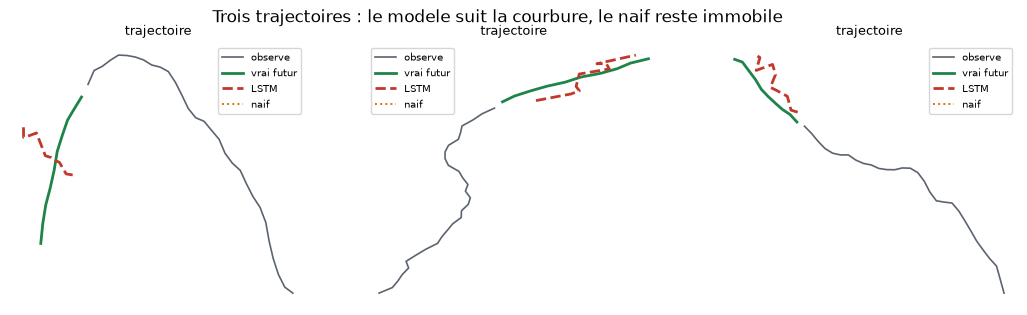

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax in axes:
    i = np.random.randint(len(obs))
    ax.plot(obs[i, :, 0], obs[i, :, 1], color="#5B6470", lw=1.2, label="observe")
    ax.plot(cible[i, :, 0], cible[i, :, 1], color="#1E8449", lw=2, label="vrai futur")
    ax.plot(pred[i, :, 0], pred[i, :, 1], color="#C0392B", lw=2, ls="--", label="LSTM")
    ax.plot(naif[i, :, 0], naif[i, :, 1], color="#D97706", lw=1.4, ls=":", label="naif")
    ax.legend(fontsize=7.5); ax.set_title("trajectoire", fontsize=9)
    ax.axis("off")
plt.suptitle("Trois trajectoires : le modele suit la courbure, le naif reste immobile")
plt.show()

## Grille d'évaluation (20 points)

| Critère | Points |
|---|---|
| Le notebook s'exécute de bout en bout | 4 |
| Découpage correct (pas de fuite) et justification | 4 |
| RMSE mesuré **et** comparé à la référence naïve | 4 |
| Une expérience contrôlée (horizon, H, GRU vs LSTM) | 4 |
| Analyse des échecs (trajectoires à fort virage) | 2 |
| Conclusion : trois limites honnêtes | 2 |

**Règle :** tout chiffre du rapport doit être reproductible.

## À vous

**1.** Faites varier l'horizon (5, 10, 20) : comment évolue le RMSE ?

**2.** Remplacez le LSTM par une GRU : gain ou perte ?

**3.** Le modèle se trompe-t-il davantage sur les trajectoires à fort virage ? Mesurez l'erreur en fonction de la courbure.

In [6]:
# ---- A VOUS ----
# 1)
# 2)
# 3)